Task: Implement a toy LWE generator, where you take $(n,q,m,\chi)$ and generate LWE instances.

The [documentation](https://doc.sagemath.org/html/en/reference/cryptography/sage/crypto/lwe.html#sage.crypto.lwe.LWE) gives us a pretty good basis (pun intended) already for LWE generation: `from sage.crypto.lwe import LWE`. Check the next two cells.

In [1]:
from sage.crypto.lwe import LWE

---BEGIN DOCUMENTATION---

Construct an LWE oracle in dimension ``n`` over a ring of order
``q`` with noise distribution ``D``.

INPUT:
- ``n`` -- dimension (integer > 0)
- ``q`` -- modulus typically > n (integer > 0)
- ``D`` -- an error distribution such as an instance of
  :class:`DiscreteGaussianDistributionIntegerSampler` or :class:`UniformSampler`
- ``secret_dist`` -- distribution of the secret (default: ``'uniform'``); one of

  - ``'uniform'`` -- secret follows the uniform distribution in `\Zmod{q}`
  - ``'noise'`` -- secret follows the noise distribution
  - ``(lb, ub)`` -- the secret is chosen uniformly from ``[lb,...,ub]``
    including both endpoints

- ``m`` -- number of allowed samples or ``None`` if no such limit exists
  (default: ``None``)
  
---END DOCUMENTATION---

On this object (say, `lwe`), you can just call it (say, `lwe()`) and it outputs a sample. If we classify $m$, then that limits the number of samples that can be generated.

For `D` (or $\chi$), it's probably best to use some of the classes that exist in SageMath via `sage.probability.probability_distribution.RealDistribution(distr, params)`, where inside the parenthesis:
- Uniform distribution on the interval $[a, b]$: `('uniform', [a,b])`
- Gaussian distribution with parameter standard deviation $\sigma$: `('gaussian', sigma)`
- Student's t-distribution with parameter degrees of freedom $\nu$: `('t', nu)`
- “Symmetric generalized normal” / ”exponential power distribution” with scale `a` ($\alpha$ in math) and shape `b` ($\beta$ in math): `('exppow', [a, b])`

In [2]:
from sage.probability.probability_distribution import RealDistribution

In [3]:
n = 20
m = 10
q = 89
secret_dist = 'uniform'

In [4]:
a=1; b=4
D = RealDistribution('exppow', [a, b])

In [5]:
D.get_random_element()

0.1154451499177287

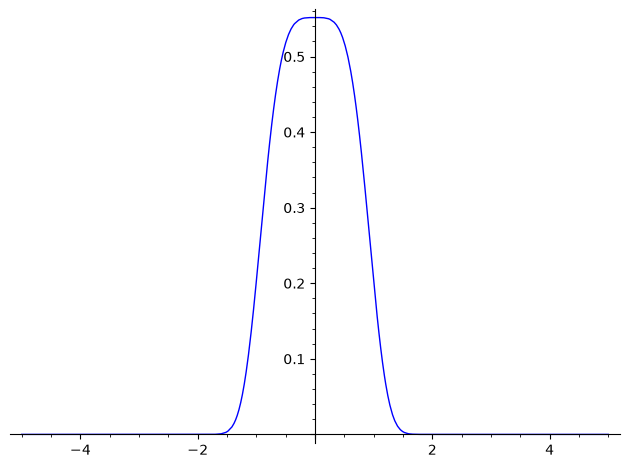

In [6]:
D.plot([-5,5])

One crucial error: `probability_distribution.RealDistribution object is not callable`. The documentation actually requires a Sampler for the error distribtution, not the distribution directly. The built-in methods for this are:
- DiscreteGaussianDistributionIntegerSampler (A Discrete Gaussian Sampler using rejection sampling.)
- UniformSampler (Uniform sampling in a range of integers.)

Another way to approach this is to wrap `RealDistribution` and create our own sampler.

In [7]:
class CustomSampler:
    def __init__(self, D):
        self.D = D

    # WARNING: sampling with rounding to the nearest integer
    def __call__(self):
        return round(self.D.get_random_element())

In [8]:
lwe_oracle = LWE(
    n=n, 
    q=q, 
    D=CustomSampler(D), # remember, rounding exppow to nearest integer
    secret_dist=secret_dist,
    m=None # we are not limiting how many samples the oracle can output
)

In [9]:
from sage.crypto.lwe import samples

In [10]:
samples(m=m, n=n, lwe=lwe_oracle)

[((35, 5, 23, 14, 73, 20, 88, 80, 56, 76, 38, 28, 27, 33, 23, 46, 12, 62, 25, 5),
  69),
 ((19, 64, 81, 84, 64, 47, 25, 47, 35, 46, 8, 60, 3, 70, 22, 85, 23, 28, 79, 29),
  16),
 ((17, 45, 27, 9, 36, 40, 46, 5, 56, 17, 67, 73, 55, 87, 5, 15, 84, 40, 53, 23),
  66),
 ((83, 33, 87, 39, 64, 35, 70, 16, 49, 12, 15, 0, 5, 69, 19, 15, 74, 21, 49, 66),
  37),
 ((3, 43, 75, 70, 9, 64, 21, 49, 56, 67, 45, 38, 33, 50, 1, 58, 50, 16, 55, 19),
  34),
 ((20, 58, 82, 9, 52, 45, 51, 22, 4, 1, 4, 81, 32, 62, 18, 0, 50, 83, 15, 21),
  43),
 ((3, 74, 83, 68, 54, 71, 79, 87, 21, 36, 72, 48, 88, 33, 2, 27, 87, 79, 79, 20),
  80),
 ((44, 79, 53, 4, 38, 60, 36, 83, 22, 10, 37, 25, 67, 68, 42, 86, 32, 50, 2, 70),
  87),
 ((9, 54, 32, 3, 78, 41, 78, 71, 15, 21, 67, 44, 11, 0, 88, 65, 50, 13, 84, 78),
  27),
 ((81, 34, 67, 26, 0, 79, 20, 21, 36, 45, 38, 55, 25, 51, 19, 57, 12, 5, 23, 77),
  13)]

If we try to ask for more samples than the predefined $m$, we get `Number of available samples exhausted.`

# What parameters should generally be used?

### Regev09 (Reg24 in my references)

In [11]:
# "modulus and the standard deviation of the noise are chosen as in [Reg09]"
S = samples(m=2, n=41, lwe='Regev')
S

[((172, 1243, 108, 1226, 1002, 888, 382, 1512, 303, 1687, 899, 888, 998, 936, 958, 1244, 1115, 502, 873, 1459, 1432, 1402, 415, 280, 1285, 1674, 900, 1531, 1377, 1124, 544, 729, 316, 1575, 929, 1062, 480, 1043, 509, 736, 1490),
  1385),
 ((1164, 1250, 808, 1232, 1520, 559, 263, 1374, 1285, 152, 541, 1310, 461, 1672, 999, 1585, 1539, 525, 1427, 1086, 1136, 1447, 1024, 915, 106, 780, 551, 119, 8, 1518, 280, 723, 1672, 586, 980, 417, 215, 1555, 1381, 1504, 233),
  1112)]

In [12]:
S[0][0].parent()

Vector space of dimension 41 over Ring of integers modulo 1693

It seems that Regev uses a modulus $q$ such that $q> n^2$ and $q$ is prime.

This is supported by page $3$ of Regev's work:
> The exact definition of $\Psi _\alpha$ will be given later. For now, it is enough to know that it is a distribution on $\mathbb Z_p$
that has the shape of a **discrete Gaussian** centered around $0$ with **standard deviation** $\alpha p$, as in Figure 1. Also,
the probability of $0$ (i.e., no error) is roughly $1/(\alpha p)$. A possible setting for the parameters is $p=O(n^2)$ and $\alpha = 1/(\sqrt n \log ^2 n)$ (in fact, these are the parameters that we use in our cryptographic application).

SageMath's `lwe.py` replicates Regev's paramters with the following: (comments added by me)
```python
secret_dist='uniform'; m=None
# modulus is chosen as the next prime number after (#vars)^2
q = ZZ(next_prime(n**2))
# secret $s$ is $\alpha \cdot q$; RR is a floating point wrapper
s = RR(1/(RR(n).sqrt() * log(n, 2)**2) * q)
# Discrete Gaussian on Lattices !!!!! (which is why it looks slightly unfamiliar)
#  s = sqrt(2pi)*\sigma   ==>   sigma = s / sqrt(2pi)
# Additionally, $q$ is the centre point (implementation trick, avoids issues with negatives) 
D = DiscreteGaussianDistributionIntegerSampler(s/sqrt(2*pi.n()), q)
LWE.__init__(self, n=n, q=q, D=D, secret_dist=secret_dist, m=m)
```

Regev also mentions that their hardness theorem only words for modulus $p > 2\sqrt n$

### Lindner & Peikert (2011) “Better Key Sizes (and Attacks) for LWE-Based Encryption”

In [13]:
S = samples(m=2, n=41, lwe='LindnerPeikert')
S

[((1303, 652, 1200, 168, 1085, 817, 524, 1864, 1811, 365, 1774, 1205, 451, 1558, 817, 1251, 2022, 2036, 657, 359, 1188, 2020, 320, 205, 56, 107, 1583, 1508, 1445, 375, 978, 1661, 307, 274, 654, 549, 680, 1364, 771, 529, 664),
  1206),
 ((567, 129, 84, 1646, 1034, 310, 1668, 714, 1406, 652, 422, 91, 1449, 1828, 1639, 1633, 143, 915, 1642, 1226, 325, 1168, 1271, 2027, 876, 1109, 136, 420, 1392, 1449, 821, 427, 521, 373, 782, 1057, 1089, 1154, 1219, 477, 603),
  613)]

In [14]:
S[0][0].parent()

Vector space of dimension 41 over Ring of integers modulo 2053

SageMath's `lwe.py` has the following for LP: (comments not added by me)
```python
if m is None:
    m = 2*n + 128
# Find c>=1 such that c*exp((1-c**2)/2))**(2*n) == 2**-40
#         (c*exp((1-c**2)/2))**(2*n) == 2**-40
#    log((c*exp((1-c**2)/2))**(2*n)) == -40*log(2)
#       (2*n)*log(c*exp((1-c**2)/2)) == -40*log(2)
#  2*n*(log(c)+log(exp((1-c**2)/2))) == -40*log(2)
#            2*n*(log(c)+(1-c**2)/2) == -40*log(2)
#              2*n*log(c)+n*(1-c**2) == -40*log(2)
#  2*n*log(c)+n*(1-c**2) + 40*log(2) == 0
c = SR.var('c')
c = find_root(2*n*log(c)+n*(1-c**2) + 40*log(2) == 0, 1, 10)
# Upper bound on s**2/t
s_t_bound = (sqrt(2) * pi / c / sqrt(2*n*log(2/delta))).n()
# Interpretation of "choose q just large enough to allow for a Gaussian parameter s>=8" in [LP2011]_
q = next_prime(floor(2**round(log(256 / s_t_bound, 2))))
# Gaussian parameter as defined in [LP2011]_
s = sqrt(s_t_bound*floor(q/4))
# Transform s into stddev
stddev = s/sqrt(2*pi.n())
D = DiscreteGaussianDistributionIntegerSampler(stddev)
LWE.__init__(self, n=n, q=q, D=D, secret_dist='noise', m=m)
```

In other words, they first limit $m$ to be $2n + 128$. 

They define integer dimensions $n_1, n_2\geq 1$ (page 336 $n=n_1=n_2$), Gaussian parameters $s_k$ and $s_e$ for key generation and encryption (page 336 $s_k=s_e=s=O(\sqrt q)$, message length $\ell = 128$ bits.

They describe parameter $c$ in Fig. 1 (p. 328): “$c$ is determined so that the probability of choosing a *bad* encryption vector $e$ is at most $2^{−40}$” ($-40$ is also described as being a statistical parameter $\kappa$). Before, they mention that `c` is based purely on $(n_1+n_2)$.

On the modulus $q$, they indeed do mention (p. 335):
> We choose the modulus $q$ to be just large enough .. to allow for a Gaussian parameter $s\geq 8$, so that the discrete Gaussian .. approximates the continuous Gaussian .. extremely well. Increasing the value of $q$ beyond this threshold appears to not increase the concrete security of our cryptosystem, and (somewhat paradoxically) may even slightly decrease it!

One last interesting note is that for the secret distribution, they also utilize Gaussian noise (p. 324, where they refer to Micciancio&Regev09 and Applebaum+09):
> A particularly important fact for our purposes is that decision-LWE becomes no easier to solve even if the secret $s$ is chosen from the error distribution $\chi$, rather than uniformly at random.